In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)


Saving CardiacSurgery&PerfusionOutcomesAnalysis.csv to CardiacSurgery&PerfusionOutcomesAnalysis (9).csv
Dataset loaded successfully!
Rows and columns: (1001, 23)


In [48]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
# Remove columns named Unnamed
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Column names and text values cleaned.")


First 5 rows:


,Record_ID,Patient_ID,Age,Sex,Weight_kg,Surgery_Type,CPB_Time_min,Cross_Clamp_Time_min,Temperature_C,ICU_Stay_days,Ventilation_hours,Total_Cost,Outcome,Complication,Reoperation,Age_Group
0,R0926,P1001,69.0,M,71.7,CABG,153.0,72.0,34.0,4.0,14.0,28800.0,Recovered,No,No,MIDDLE-AGED
1,R0794,P1002,61.0,M,65.5,CABG,91.0,83.0,32.5,1.0,16.0,19900.0,Stable,No,No,MIDDLE-AGED
2,R0479,P1003,71.0,F,80.5,Valve Replacement,106.0,65.0,33.4,6.0,17.0,31200.0,Recovered,No,No,SENIOR
3,R0002,P1004,81.0,F,94.8,CABG,89.0,89.0,31.1,3.0,7.0,NaN,Recovered,No,No,SENIOR
4,R0481,P1005,60.0,M,49.7,CABG,101.0,86.0,31.2,5.0,7.0,24350.0,Recovered,No,No,MIDDLE-AGED



Column names:
['Record_ID', 'Patient_ID', 'Age', 'Sex', 'Weight_kg', 'Surgery_Type', 'CPB_Time_min', 'Cross_Clamp_Time_min', 'Temperature_C', 'ICU_Stay_days', 'Ventilation_hours', 'Total_Cost', 'Outcome', 'Complication', 'Reoperation', 'Age_Group']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Record_ID             1000 non-null   object 
 1   Patient_ID            1000 non-null   object 
 2   Age                   988 non-null    float64
 3   Sex                   1000 non-null   object 
 4   Weight_kg             985 non-null    float64
 5   Surgery_Type          1000 non-null   object 
 6   CPB_Time_min          990 non-null    float64
 7   Cross_Clamp_Time_min  1000 non-null   float64
 8   Temperature_C         992 non-null    float64
 9   ICU_Stay_days         993 non-null    float64
 10  Vent

,Age,Weight_kg,CPB_Time_min,Cross_Clamp_Time_min,Temperature_C,ICU_Stay_days,Ventilation_hours,Total_Cost
count,988.000000,985.000000,990.000000,1000.000000,992.000000,993.000000,1000.000000,990.000000
mean,63.053644,76.503858,115.764646,72.934000,31.976815,3.336354,12.151000,27155.151515
std,11.913916,14.693152,34.486793,18.231238,1.358334,1.769949,5.328094,7079.934957
min,4.000000,40.000000,35.000000,20.000000,28.500000,1.000000,3.000000,13750.000000
25%,55.000000,67.000000,95.000000,61.000000,31.100000,2.000000,8.000000,22750.000000
50%,63.000000,76.100000,112.500000,72.000000,31.900000,3.000000,12.000000,25550.000000
75%,71.000000,85.300000,132.000000,84.000000,32.800000,4.000000,16.000000,28850.000000
max,90.000000,210.000000,500.000000,142.000000,45.000000,11.000000,29.000000,49050.000000


Missing values per column:
Record_ID                1
Patient_ID               1
Age                     13
Sex                      1
Weight_kg               16
Surgery_Type             1
CPB_Time_min            11
Cross_Clamp_Time_min     1
Temperature_C            9
ICU_Stay_days            8
Ventilation_hours        1
Total_Cost              11
Outcome                  1
Complication             1
Reoperation              1
Age_Group               13
dtype: int64

Total missing values:
90
Column names and text values cleaned.


In [41]:
columns = ["Age", "CPB_Time_min", "ICU_Stay_days"]

analysis_df = df.dropna(subset=columns).copy()

correlation = analysis_df[columns].corr()

display(correlation)

,Age,CPB_Time_min,ICU_Stay_days
Age,1.000000,0.013946,0.144213
CPB_Time_min,0.013946,1.000000,0.360204
ICU_Stay_days,0.144213,0.360204,1.000000


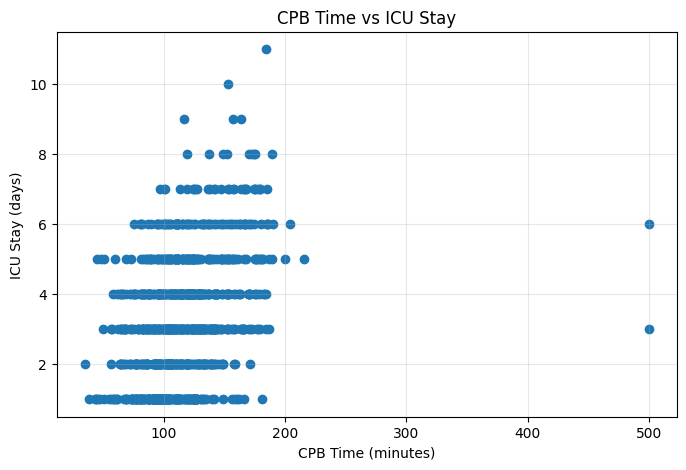

In [42]:
plt.figure(figsize=(8, 5))

plt.scatter(
    analysis_df["CPB_Time_min"],
    analysis_df["ICU_Stay_days"]
)

plt.title("CPB Time vs ICU Stay")
plt.xlabel("CPB Time (minutes)")
plt.ylabel("ICU Stay (days)")
plt.grid(True, alpha=0.3)
plt.show()

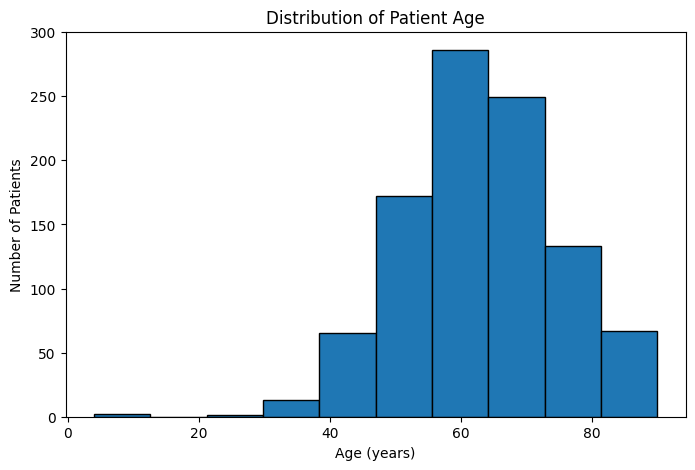

In [43]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"].dropna(), bins=10, edgecolor="black")

plt.title("Distribution of Patient Age")
plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")
plt.show()

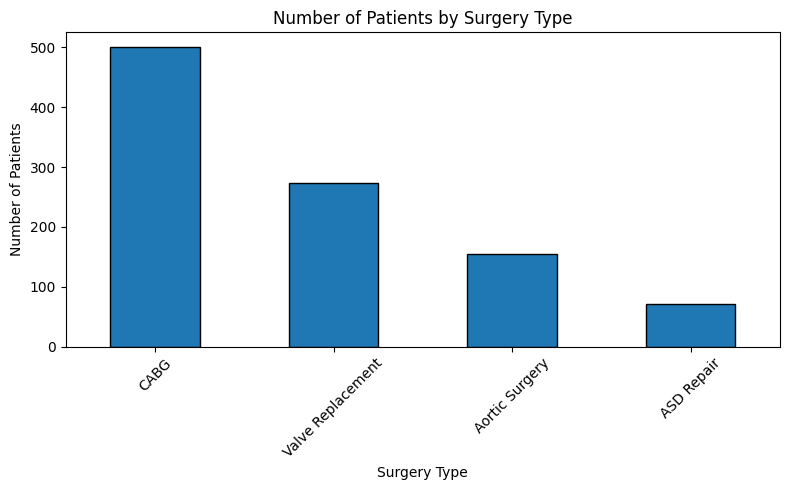

In [44]:
df["Surgery_Type"].value_counts().plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Number of Patients by Surgery Type")
plt.xlabel("Surgery Type")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

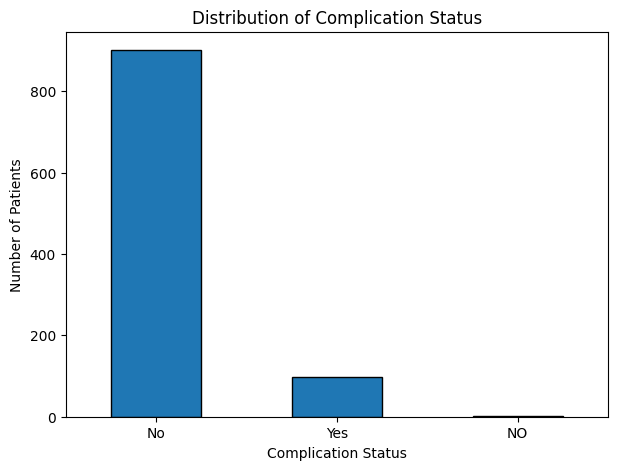

In [45]:
df["Complication"].value_counts().plot(
    kind="bar",
    figsize=(7, 5),
    edgecolor="black"
)

plt.title("Distribution of Complication Status")
plt.xlabel("Complication Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

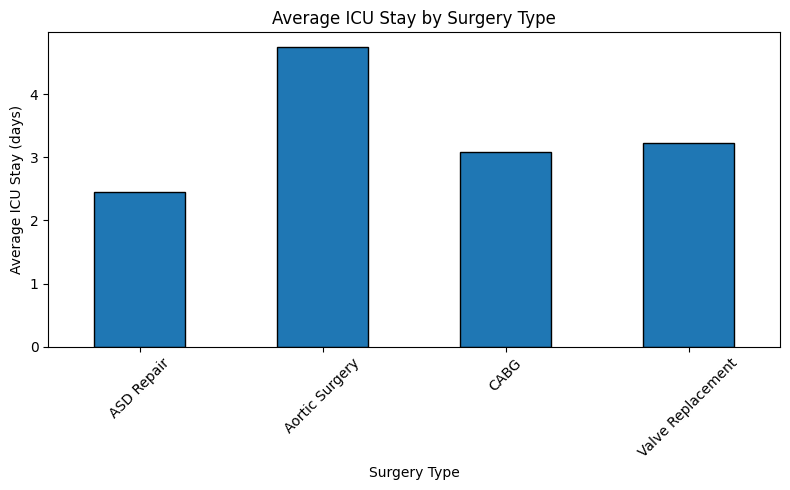

In [46]:
df.groupby("Surgery_Type")["ICU_Stay_days"].mean().plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Average ICU Stay by Surgery Type")
plt.xlabel("Surgery Type")
plt.ylabel("Average ICU Stay (days)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()